In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import os
import random
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense,Dropout,Conv2D,MaxPooling2D,Flatten
from keras.models import load_model
import cv2
from tensorflow.keras import layers

In [105]:
train_path=r'c:\Users\HP\Downloads\Fast Food Classification\Fast Food Classification V2\Train'
test_path=r'c:\Users\HP\Downloads\Fast Food Classification\Fast Food Classification V2\Test'

# Check CLasses in Dataset

check CLasses in train path

In [106]:
classes = os.listdir(train_path)
print("Classes in test set: ", classes)
for label, class_name in enumerate(classes):
    print(f"Class {label}: {class_name}")

Classes in test set:  ['Donut', 'Pizza', 'Taco']
Class 0: Donut
Class 1: Pizza
Class 2: Taco


check classes i test path

In [107]:
classes = os.listdir(test_path)
print("Classes in test set: ", classes)
for label, class_name in enumerate(classes):
    print(f"Class {label}: {class_name}")

Classes in test set:  ['Donut', 'Pizza', 'Taco']
Class 0: Donut
Class 1: Pizza
Class 2: Taco


# Count Images

Train imaes

In [108]:
for i in classes:
    folder=os.path.join(train_path,i)
    len_images=len([file for file in os.listdir(folder)
                    if file.lower().endswith(('.jpg','.png','.jpeg'))])
    print(f"Number of images in {i}: {len_images}")

Number of images in Donut: 1500
Number of images in Pizza: 1500
Number of images in Taco: 1500


test images

In [109]:
for i in classes:
    folder=os.path.join(test_path, i)
    count_images=len([file for file in os.listdir(folder)
                  if file.lower().endswith(('.png', '.jpg', '.jpeg'))])
    print(f"Number of images in {i}: {count_images}")

Number of images in Donut: 200
Number of images in Pizza: 200
Number of images in Taco: 100


# Samples Images

In [110]:
import random

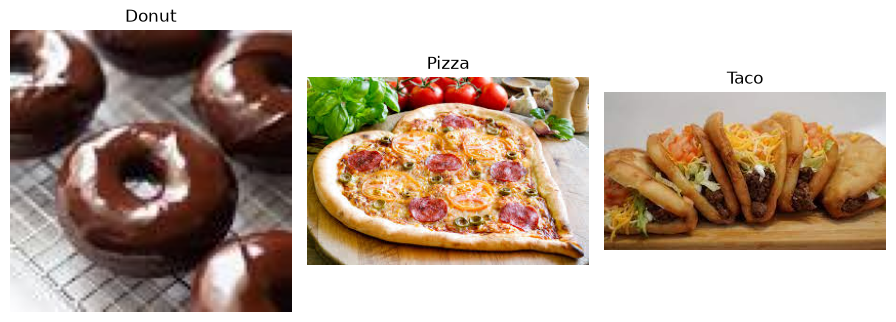

In [111]:
import random
plt.figure(figsize=(15, 8))
for i, label in enumerate(classes):
    folder = os.path.join(train_path, label)
    images = [
        file for file in os.listdir(folder)
        if file.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]
    if len(images) > 0:
        image_path = os.path.join(folder, random.choice(images))
        image = plt.imread(image_path)
        plt.subplot(2, 5, i + 1)
        plt.imshow(image)
        plt.title(label)
        plt.axis("off")

plt.tight_layout()
plt.show()

# Data Generator

1. Normalize images

2. Reduce overfitting

3. Improve generalization



In [112]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [113]:
train_dataden=ImageDataGenerator(
    rescale=1.0/255.0,#Convert pixel into 0-1
    rotation_range=20,# rotate image
    zoom_range=0.15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    horizontal_flip=True
    
)

Why?

Test dataset ka purpose ye check karna hai ke:

Model unseen/original images par kitna accurately perform karta hai.

Agar test images ko randomly rotate, zoom, flip etc. karenge, to evaluation conditions change ho jayengi.

In [114]:
test_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
)

# Train Data

flow_from_directory==>Folder ke andar classes ke folders ko automatically read karo aur images + labels bana do.

In [115]:
train_data = train_dataden.flow_from_directory(
    train_path,
    target_size=(128,128),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

Found 4500 images belonging to 3 classes.


TRAIN DATA
shuffle=True
      ↓
Model ko learning karwani hai
Random order useful hai


TEST DATA
shuffle=False
      ↓
Model ko evaluate karna hai
Original order preserve karna useful hai

# Test Data

In [116]:
test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(128,128),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 500 images belonging to 3 classes.


In [165]:
classes

['Donut', 'Pizza', 'Taco']

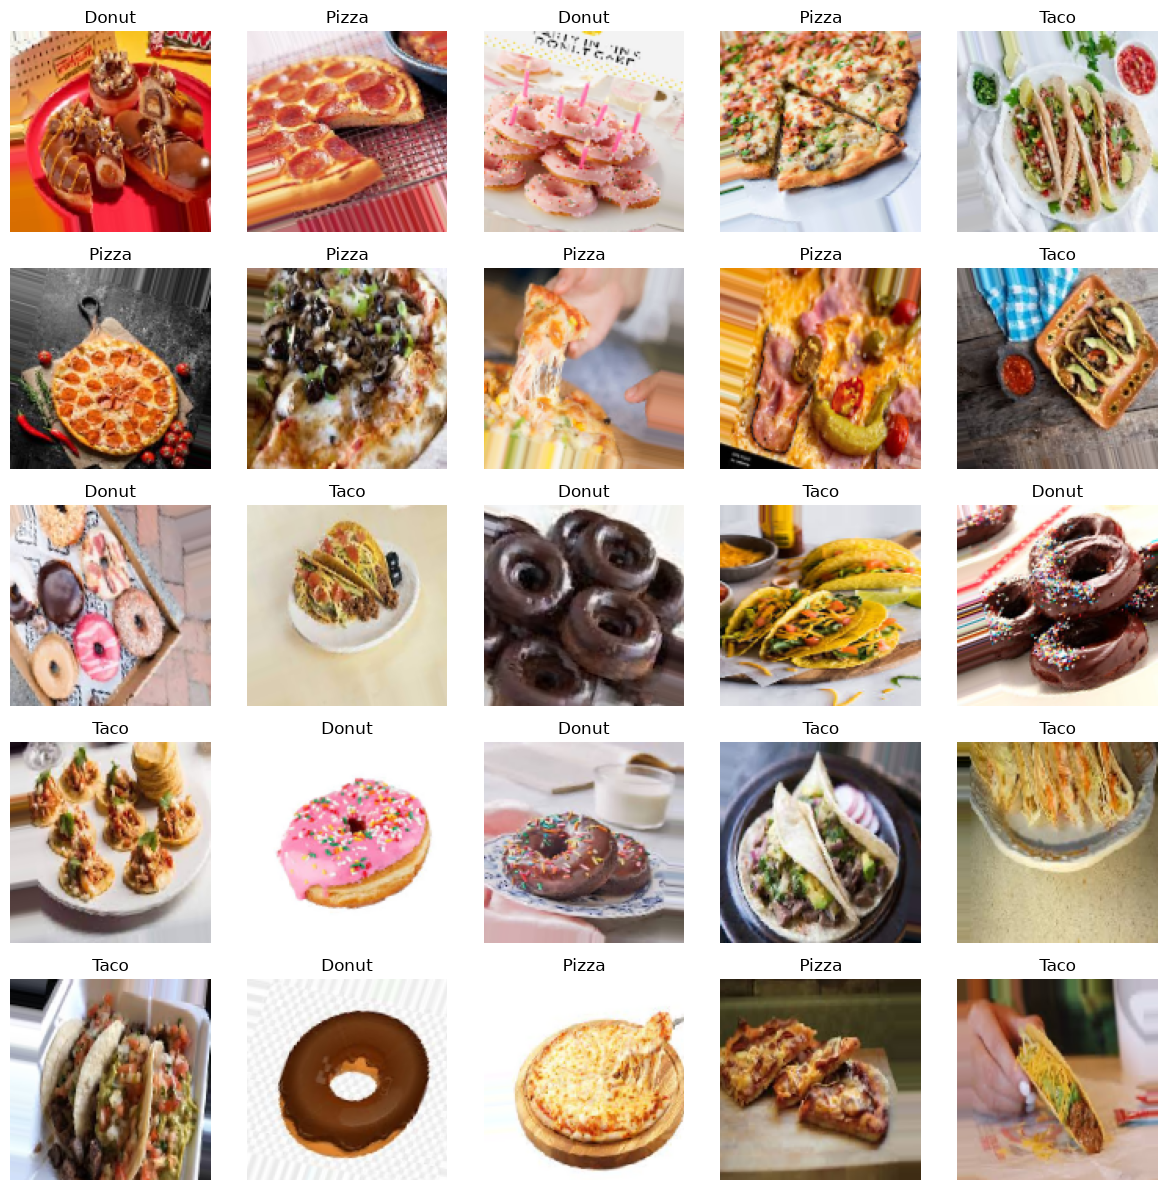

In [168]:
image, label = next(train_data)

plt.figure(figsize=(12, 12))
for i in range(min(25, len(image))):
    plt.subplot(5, 5, i + 1)
    plt.imshow(image[i])
    plt.title(classes[np.argmax(label[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Model

In [118]:
model = Sequential([

    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(256, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(3, activation='softmax')
])

c:\Users\HP\OneDrive\Desktop\DEEP LEARNING\tf_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Complie

In [119]:
from tensorflow.keras.optimizers import Adam

adam = Adam(learning_rate=0.001)

In [120]:
model.compile(
    optimizer=adam,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Summary

In [121]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_16 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,568,579 (5.98 MB)

 Trainable params: 1,568,579 (5.98 MB)

 Non-trainable params: 0 (0.00 B)

# Fit

In [122]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [123]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=12,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

In [125]:
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=100,

)

Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 71s 505ms/step - accuracy: 0.5956 - loss: 0.8902 - val_accuracy: 0.7360 - val_loss: 0.6292
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 73s 514ms/step - accuracy: 0.7138 - loss: 0.7260 - val_accuracy: 0.7400 - val_loss: 0.6020
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 79s 560ms/step - accuracy: 0.7611 - loss: 0.6231 - val_accuracy: 0.5980 - val_loss: 0.8864
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 77s 543ms/step - accuracy: 0.7638 - loss: 0.6115 - val_accuracy: 0.7920 - val_loss: 0.4695
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 71s 503ms/step - accuracy: 0.7871 - loss: 0.5576 - val_accuracy: 0.7860 - val_loss: 0.4803
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 71s 503ms/step - accuracy: 0.7956 - loss: 0.5339 - val_accuracy: 0.8080 - val_loss: 0.5001
Epoch 7/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 68s 483ms/step - accuracy: 0.7887 - loss: 0.5376 - val_accuracy: 0.7700 - val_loss: 0.5650
Epoch 8/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 66s 469ms/step - accuracy: 0.7958 -

In [126]:
loss, accuracy = model.evaluate(
    test_data
)
print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 187ms/step - accuracy: 0.8760 - loss: 0.5908
Validation Loss: 0.5907825231552124
Validation Accuracy: 0.8759999871253967


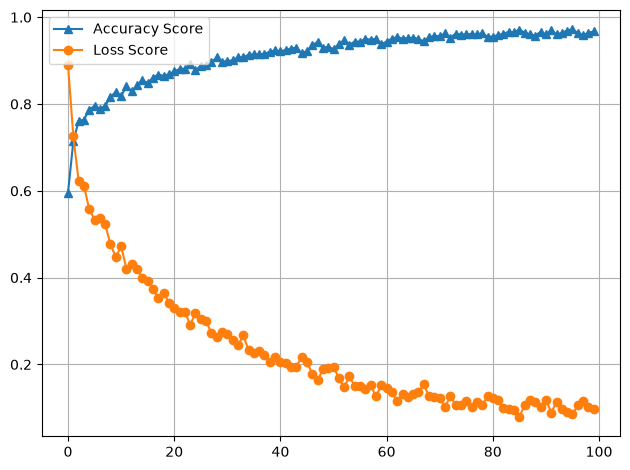

In [128]:
plt.plot(history.history['accuracy'],label='Accuracy Score',marker='^')
plt.plot(history.history['loss'],label='Loss Score',marker='o')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [129]:
from sklearn.metrics import accuracy_score

In [130]:
prediction=model.predict(test_data,verbose=1)
y_pred=np.argmax(prediction,axis=1)
y_true=test_data.classes
accuracy=accuracy_score(y_true,y_pred)
print("Accuracy Acore",accuracy)

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 207ms/step
Accuracy Acore 0.876


In [137]:
class_names=['Taco','Pizza','Donut']

In [150]:
classes

['Donut', 'Pizza', 'Taco']

In [170]:
classes_test=os.listdir(train_path)
classes_test

['Donut', 'Pizza', 'Taco']

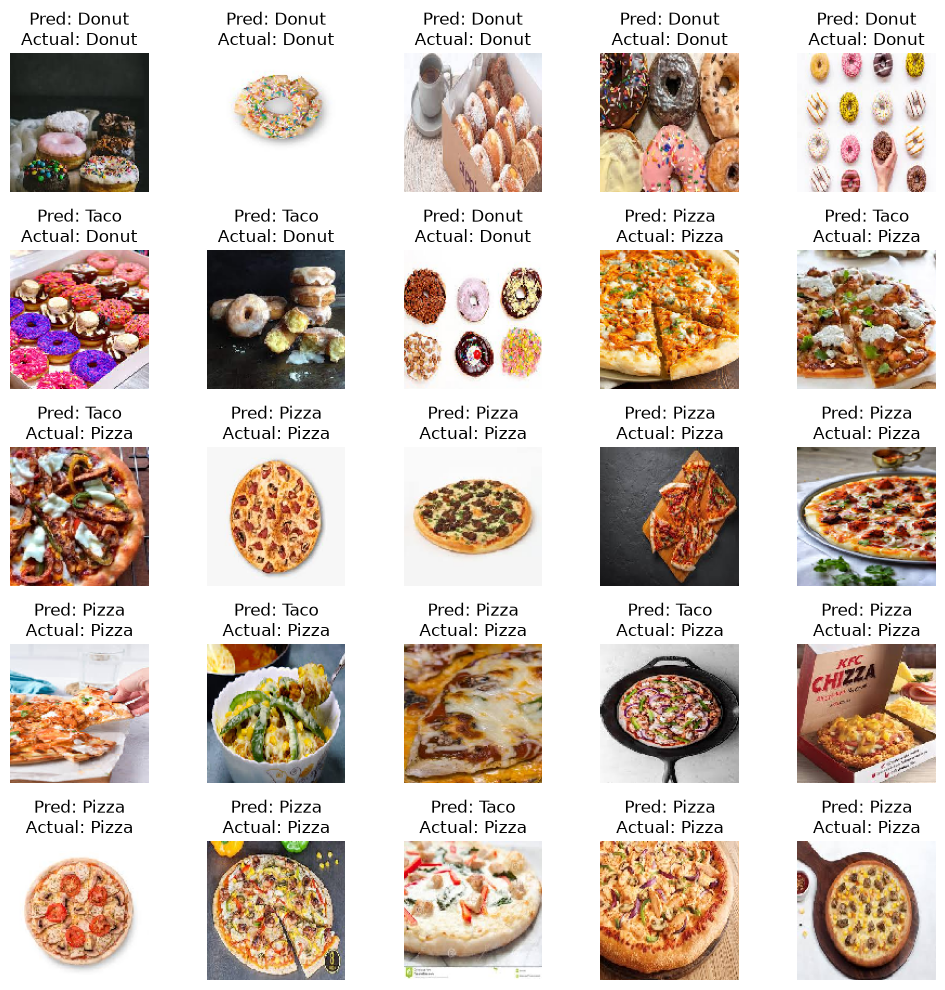

In [171]:
images = []
labels = []

for _ in range(10):
    image, label = next(test_data)

    images.extend(image)
    labels.extend(label)

    if len(images) >= 100:
        break

images = np.array(images)
labels = np.array(labels)

plt.figure(figsize=(10, 10))

for i in range(25):

    plt.subplot(5, 5, i + 1)

    plt.imshow(images[i])

    actual = classes_test[np.argmax(labels[i])]
    pred = classes_test[np.argmax(model.predict(images[i:i+1], verbose=0))]

    plt.title(f"Pred: {pred}\nActual: {actual}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [172]:
wrong_indices=np.where(y_pred!=y_true)
len(wrong_indices)

1

In [173]:
model.save('FAST_FOOD_CLASSIFICATION.keras')

In [174]:
model=load_model('FAST_FOOD_CLASSIFICATION.keras')

In [175]:
import cv2

In [176]:
image_path=r'c:\Users\HP\Downloads\Fast Food Classification\Fast Food Classification V2\Valid\Pizza\Pizza-Valid (159).jpeg'

In [177]:
image=cv2.imread(image_path)

In [178]:
image=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

In [ ]:
image=cv2.resize(image,(128,128))


In [180]:
image = image.astype("float32") / 255.0

In [181]:
test_image=np.expand_dims(image, axis=0)
print(test_image.shape)

(1, 128, 128, 3)


In [182]:
prediction = model.predict(test_image)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step


In [184]:
class_names

{0: 'Taco', 1: 'Pizza', 2: 'Donut'}

In [185]:
predict_index=np.argmax(prediction[0])
predict_class=class_names[predict_index]
confidence=prediction[0][predict_index]

In [186]:
print("Prediction:", predict_class)
print("Confidence:", confidence, "%")

Prediction: Pizza
Confidence: 0.9962315 %
